# Comparison of F-test and mutual information: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/feature_selection/plot_f_test_vs_mi.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/feature_selection/plot_f_test_vs_mi.html)).

**Scenario:** three uniform features, `y = x_1 + sin(6 pi x_2) + 0.1 N(0, 1)`. The univariate F-test
(`f_regression`) ranks the linear feature `x_1` first; mutual information (`mutual_info_regression`)
ranks the sinusoidal feature `x_2` first. Both mark `x_3` as irrelevant. The notebook also exercises
`r_regression` and `SelectKBest` with both scorers (the selectors the example's scores feed in practice).

**Adaptations:**
- The data are generated once in Python with the example's `np.random.seed(0)` code and shared with Moxie.
- The example calls `mutual_info_regression(X, y)` with `random_state=None`, i.e. it consumes NumPy's
  *global* legacy stream right after the data were drawn. Moxie has no access to NumPy's global state,
  so the Mojo program reproduces the same stream explicitly: it creates Moxie's legacy-compatible
  `RandomState(0)`, draws the same 3000 uniforms and 1000 normals (checked against the shared data),
  and passes that advanced stream to Moxie's `mutual_info_regression(..., random_state=stream)` overload.
- `SelectKBest` with mutual information uses `random_state=0` on both sides
  (`functools.partial` in Python, `MutualInfoScorer(random_state=0)` in Mojo).

**Determinism:** deterministic. The data use a fixed seed and the MI jitter comes from the same
MT19937 legacy stream on both sides, so scores are compared numerically.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("feature_selection/plot_f_test_vs_mi")

## 1. scikit-learn (Python reference)

The official example code, unchanged apart from the smaller figure.

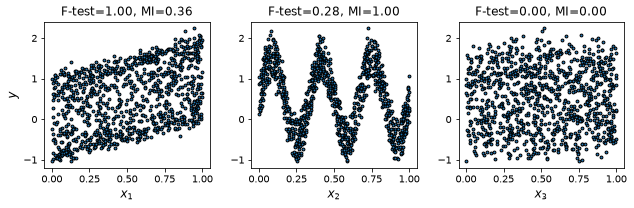

In [2]:
import matplotlib.pyplot as plt
import numpy as np

from sklearn.feature_selection import f_regression, mutual_info_regression

np.random.seed(0)
X = np.random.rand(1000, 3)
y = X[:, 0] + np.sin(6 * np.pi * X[:, 1]) + 0.1 * np.random.randn(1000)

f_test, _ = f_regression(X, y)
f_test /= np.max(f_test)

mi = mutual_info_regression(X, y)
mi /= np.max(mi)

plt.figure(figsize=(9, 3), dpi=72)
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.scatter(X[:, i], y, edgecolor="black", s=8)
    plt.xlabel("$x_{}$".format(i + 1), fontsize=12)
    if i == 0:
        plt.ylabel("$y$", fontsize=12)
    plt.title("F-test={:.2f}, MI={:.2f}".format(f_test[i], mi[i]), fontsize=12)
plt.tight_layout()
plt.show()

Additional reference values for the parity checks: raw statistics, `r_regression`, and `SelectKBest` with each scorer.

In [3]:
from functools import partial
from sklearn.feature_selection import SelectKBest, r_regression

sk_f, sk_p = f_regression(X, y)
sk_r = r_regression(X, y)
sk_f_nc, sk_p_nc = f_regression(X, y, center=False)
np.random.seed(0); np.random.rand(1000, 3); np.random.randn(1000)
sk_mi_raw = mutual_info_regression(X, y)          # same global stream position as the example
sk_mi_seed = mutual_info_regression(X, y, random_state=0)
sk_kbest_f = SelectKBest(f_regression, k=1).fit(X, y)
sk_kbest_mi = SelectKBest(partial(mutual_info_regression, random_state=0), k=1).fit(X, y)
print("f_regression:", sk_f, "\nmutual_info (global stream):", sk_mi_raw)
print("SelectKBest(f_regression, k=1) support:", sk_kbest_f.get_support(indices=True))
print("SelectKBest(mutual_info, k=1) support:", sk_kbest_mi.get_support(indices=True))
nb.share(X=X, y=y)

f_regression: [187.42118421  52.52357392   0.47268298] 
mutual_info (global stream): [0.31431334 0.86235026 0.        ]
SelectKBest(f_regression, k=1) support: [0]
SelectKBest(mutual_info, k=1) support: [1]


## 2. Moxie (native Mojo)

The same scenario through `moxie.feature_selection`. Python only supplies the data files.

In [4]:
%%mojo f_test_vs_mi
import numojo as nm
from moxie._random import RandomState
from moxie.feature_selection import (
    f_regression, r_regression, mutual_info_regression, MutualInfoScorer,
    SelectKBest, BuiltinScorer, SelectionParameter,
)
from moxie_nb_io import load, save, save_ints


def main() raises:
    var X = load("X")
    var y = load("y")
    # Reproduce np.random.seed(0); np.random.rand(1000, 3); np.random.randn(1000)
    var stream = RandomState(0)
    var max_gap = Float64(0)
    for i in range(3000):
        max_gap = max(max_gap, abs(stream.random_sample() - Float64(X.item(i // 3, i % 3))))
    var noise = nm.zeros[DType.float64](nm.Shape(1000))
    for i in range(1000):
        noise.unsafe_set(i, stream.standard_normal())
    print("max |uniform draw - shared X| =", max_gap)
    save("noise", noise)

    var f = f_regression(X, y)
    save("f", f.scores)
    save("p", f.pvalues.value())
    save("r", r_regression(X, y))
    var f_nc = f_regression(X, y, center=False)
    save("f_nc", f_nc.scores)
    save("p_nc", f_nc.pvalues.value())

    var X_work = X.copy()
    save("mi_raw", mutual_info_regression(X_work, y, random_state=stream))
    save("mi_seed", mutual_info_regression(X_work, y, random_state=0))

    var kbest_f = SelectKBest(BuiltinScorer("f_regression"), k=SelectionParameter(1))
    _ = kbest_f.fit(X, y.copy())
    save_ints("kbest_f_support", kbest_f.get_support(True)[List[Int]].copy())
    save("kbest_f_scores", kbest_f.scores_())
    var kbest_mi = SelectKBest(MutualInfoScorer(classification=False, random_state=0), k=SelectionParameter(1))
    _ = kbest_mi.fit(X, y.copy())
    save_ints("kbest_mi_support", kbest_mi.get_support(True)[List[Int]].copy())
    save("kbest_mi_scores", kbest_mi.scores_())
    print("pvalues_ is None for MI:", not kbest_mi.pvalues_())

max |uniform draw - shared X| = 0.0
pvalues_ is None for MI: True


## 3. Side by side and parity

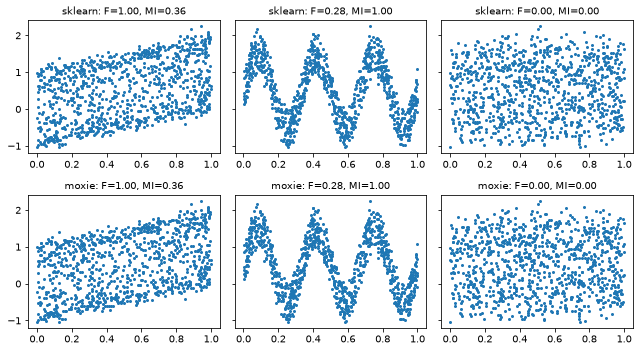

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
legacy normal stream,PASS,"(1000,)","(1000,)",0,0,"rtol=1e-15, atol=1e-15",,same MT19937 words and polar Box-Muller; a last-bit log/sqrt difference is the only freedom
f_regression scores,PASS,"(3,)","(3,)",8.53e-14,6.81e-15,"rtol=1e-10, atol=0",,Float64 correlation; dot-product and norm reduction order differs from NumPy/BLAS
f_regression pvalues,PASS,"(3,)","(3,)",2.69e-14,5.46e-14,"rtol=1e-11, atol=1e-300",,"native F tail (Lentz continued fraction, Numax libm exp/log) vs scipy fdtrc: ~1e-13; score rounding is amplified by |dlog p/dlog F| <= 80 here"
r_regression,PASS,"(3,)","(3,)",8.33e-17,3.35e-15,"rtol=1e-10, atol=0",,as f_regression scores
f_regression(center=False) scores,PASS,"(3,)","(3,)",1.71e-12,2.39e-15,"rtol=1e-10, atol=0",,as above
f_regression(center=False) pvalues,PASS,"(3,)","(3,)",3.62e-50,4.01e-13,"rtol=1e-11, atol=1e-300",,as above
mutual_info_regression (example stream),PASS,"(3,)","(3,)",4e-15,5.65e-15,"rtol=1e-09, atol=1e-12",,same jitter stream and Kraskov estimator; digamma via harmonic numbers and scaling reductions differ in the last bits
mutual_info_regression(random_state=0),PASS,"(3,)","(3,)",4e-15,5.65e-15,"rtol=1e-09, atol=1e-12",,as above
normalised F-test (plot titles),PASS,"(3,)","(3,)",5.55e-17,7.39e-15,"rtol=1e-10, atol=0",,ratio of the scores above
normalised MI (plot titles),PASS,"(3,)","(3,)",3.72e-15,1.02e-14,"rtol=1e-09, atol=0",,ratio of the scores above


In [5]:
mx = nb.results["f_test_vs_mi"]
mx_f = mx["f"] / mx["f"].max()
mx_mi = mx["mi_raw"] / mx["mi_raw"].max()
fig, axes = plt.subplots(2, 3, figsize=(9, 5), dpi=72, sharey=True)
for row, (label, f_vals, mi_vals) in enumerate([("sklearn", f_test, mi), ("moxie", mx_f, mx_mi)]):
    for i in range(3):
        ax = axes[row, i]
        ax.scatter(X[:, i], y, s=4)
        ax.set_title(f"{label}: F={f_vals[i]:.2f}, MI={mi_vals[i]:.2f}", fontsize=10)
plt.tight_layout(); plt.show()
moxie_nb.side_by_side(sklearn=np.vstack([f_test, mi]), moxie=np.vstack([mx_f, mx_mi]))

np.random.seed(0); np.random.rand(1000, 3); sk_noise = np.random.randn(1000)
nb.compare("legacy normal stream", sk_noise, mx["noise"], rtol=1e-15, atol=1e-15,
           reason="same MT19937 words and polar Box-Muller; a last-bit log/sqrt difference is the only freedom")
nb.compare("f_regression scores", sk_f, mx["f"], rtol=1e-10,
           reason="Float64 correlation; dot-product and norm reduction order differs from NumPy/BLAS")
nb.compare("f_regression pvalues", sk_p, mx["p"], rtol=1e-11, atol=1e-300,
           reason="native F tail (Lentz continued fraction, Numax libm exp/log) vs scipy fdtrc: ~1e-13; score rounding is amplified by |dlog p/dlog F| <= 80 here")
nb.compare("r_regression", sk_r, mx["r"], rtol=1e-10, reason="as f_regression scores")
nb.compare("f_regression(center=False) scores", sk_f_nc, mx["f_nc"], rtol=1e-10, reason="as above")
nb.compare("f_regression(center=False) pvalues", sk_p_nc, mx["p_nc"], rtol=1e-11, atol=1e-300, reason="as above")
nb.compare("mutual_info_regression (example stream)", sk_mi_raw, mx["mi_raw"], rtol=1e-9, atol=1e-12,
           reason="same jitter stream and Kraskov estimator; digamma via harmonic numbers and scaling reductions differ in the last bits")
nb.compare("mutual_info_regression(random_state=0)", sk_mi_seed, mx["mi_seed"], rtol=1e-9, atol=1e-12, reason="as above")
nb.compare("normalised F-test (plot titles)", f_test, mx_f, rtol=1e-10, reason="ratio of the scores above")
nb.compare("normalised MI (plot titles)", mi, mx_mi, rtol=1e-9, reason="ratio of the scores above")
nb.compare("SelectKBest(f_regression, k=1) support", sk_kbest_f.get_support(indices=True), mx["kbest_f_support"], exact=True)
nb.compare("SelectKBest(f_regression) scores_", sk_kbest_f.scores_, mx["kbest_f_scores"], rtol=1e-10, reason="as f_regression scores")
nb.compare("SelectKBest(mutual_info, k=1) support", sk_kbest_mi.get_support(indices=True), mx["kbest_mi_support"], exact=True)
nb.compare("SelectKBest(mutual_info) scores_", sk_kbest_mi.scores_, mx["kbest_mi_scores"], rtol=1e-9, atol=1e-12, reason="as MI above")
nb.note("pvalues_ for MI selector", "ADAPTED", "sklearn stores pvalues_=None; Moxie pvalues_() returns an empty Optional")
nb.report()
nb.assert_parity()